In [34]:
# --- environment ---------------------------------------------------------------
# This notebook was written against the `scnomehic` conda environment.
#     conda env create -f env/scnomehic.yml && conda activate scnomehic
# See env/README.md for which notebook uses which environment.
_ENV_EXPECTED = "scnomehic"
import os as _os, sys as _sys
if _os.path.basename(_sys.prefix) != _ENV_EXPECTED:
    print(f"[env] expected the '{_ENV_EXPECTED}' environment, running in "
          f"'{_os.path.basename(_sys.prefix)}' ({_sys.prefix}). See env/README.md.",
          file=_sys.stderr)

# --- repo paths: edit paths.yaml at the repository root, not this notebook ---
# Cached so that re-running this cell still works after it has chdir'd away.
import os as _os, sys as _sys
if "REPO_ROOT" not in globals():
    _r = _os.getcwd()
    while _r != "/" and not _os.path.exists(_os.path.join(_r, "paths.py")):
        _r = _os.path.dirname(_r)
    assert _os.path.exists(_os.path.join(_r, "paths.py")), \
        "paths.py not found above the working directory -- start Jupyter inside the repository"
    REPO_ROOT = _r
_sys.path.insert(0, REPO_ROOT)
from paths import DATA, REFERENCE, SOFTWARE, WORK, TMP, CONDA_SH, CONDA_ENVS

# --- imports & config ---
import os, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt, cooler
warnings.filterwarnings("ignore")
from cooler import balance_cooler
from hicrep import hicrepSCC
from hicrep.utils import readMcool

DUMPS       = TMP + "/bulk_gm/pipeline/hic_comparison/dumps"
OUT_FIG_DIR = WORK + "/gm12878_cellline/hic_comparison/figures"
os.makedirs(OUT_FIG_DIR, exist_ok=True)

LAB        = {2_500_000: "2.5Mb", 1_000_000: "1Mb", 500_000: "500kb", 250_000: "250kb"}
CHROMS     = [f"chr{i}" for i in range(1, 23)]
H_SMOOTH   = 2            # HiCRep smoothing window
PCT        = 95           # color-scale percentile for heatmaps
COV_FRAC   = 0.2          # heatmap: drop bins with coverage < COV_FRAC * median
MAD_THRESH = 8.0          # heatmap: also drop bins > MAD_THRESH MADs below median log-cov (centromere shoulders)
DILATE     = 1            # heatmap: expand the dropped centromere/telomere set by +/- this many bins
BULK, PSEUDO = "newbulk", "gm_pseudobulk_dedup"   # dump prefixes (PSEUDO deduped 2026-06-04; original prefix "gm_pseudobulk")


In [35]:
# --- core functions ---
def load_matrix(sample, chrom, bin_size):
    """Load a juicer 'observed NONE' dump into a dense symmetric matrix."""
    path = f"{DUMPS}/{sample}_{LAB[bin_size]}_{chrom}.txt"
    if not os.path.exists(path) or os.path.getsize(path) == 0:
        return np.zeros((0, 0))
    df = pd.read_csv(path, sep="\t", header=None, names=["s1", "s2", "c"]).dropna()
    if df.empty:
        return np.zeros((0, 0))
    b1 = (df.s1 // bin_size).astype(int).values
    b2 = (df.s2 // bin_size).astype(int).values
    n = int(max(b1.max(), b2.max()) + 1)
    m = np.zeros((n, n))
    m[b1, b2] = df.c.values; m[b2, b1] = df.c.values
    return m

def low_cov_bins(mat, frac=COV_FRAC, mad_thresh=MAD_THRESH, dilate=DILATE):
    """Bins to remove as centromere / telomere / unmappable, for HEATMAP display only.

    A plain `coverage < frac*median` cutoff leaves a residual centromere cross: the empty
    core is caught, but the partially-depleted *shoulder* bins flanking it (and shallow
    telomere bins) sit above the cutoff and survive (e.g. chr18 pseudobulk @1Mb). So combine
    three signals and then dilate:
      - empty bins (coverage == 0),
      - robust MAD cutoff: log-coverage > mad_thresh MADs below the median (catches shoulders),
      - hard fraction cutoff: coverage < frac * median,
    then expand the flagged set by +/-`dilate` bins so the immediate flanks go too.
    """
    rs = mat.sum(1); n = len(rs); pos = rs > 0
    bad = ~pos
    if pos.sum() > 2:
        lg = np.log(rs[pos]); med = np.median(lg); mad = np.median(np.abs(lg - med)) or 1.0
        z = np.full(n, -np.inf); z[pos] = (np.log(rs[pos]) - med) / mad
        bad |= (z < -mad_thresh)
        bad |= (rs < frac * np.median(rs[pos]))
    if dilate > 0 and bad.any():
        idx = np.where(bad)[0]
        for d in range(1, dilate + 1):
            bad[np.clip(idx - d, 0, n - 1)] = True
            bad[np.clip(idx + d, 0, n - 1)] = True
    return np.where(bad)[0]

def ic_balance(mat, chrom, bin_size):
    """Coverage balancing: cooler iterative correction with mad_max bad-bin filtering,
    rescaled to mean off-diagonal = 1 so two depths are directly comparable. All-positive."""
    n = mat.shape[0]
    if n == 0:
        return mat
    bins = pd.DataFrame({"chrom": [chrom]*n,
                         "start": np.arange(0, n*bin_size, bin_size, dtype=np.int64),
                         "end":   np.arange(bin_size, (n+1)*bin_size, bin_size, dtype=np.int64)})
    iu, ju = np.triu_indices(n); c = mat[iu, ju]; k = c > 0
    pix = pd.DataFrame({"bin1_id": iu[k].astype(np.int64), "bin2_id": ju[k].astype(np.int64), "count": c[k].astype(float)})
    tmp = f"/tmp/_ic_{os.getpid()}.cool"
    if os.path.exists(tmp): os.remove(tmp)
    cooler.create_cooler(tmp, bins=bins, pixels=pix, dtypes={"count": "float64"}, ordered=True, symmetric_upper=True)
    try:
        bias, _ = balance_cooler(cooler.Cooler(tmp), ignore_diags=1, mad_max=5, min_nnz=1, max_iters=300, tol=1e-5, store=False)
    except Exception:
        return mat
    w = np.nan_to_num(np.asarray(bias), nan=0.0)
    bal = mat * np.outer(w, w)
    off = ~np.eye(n, dtype=bool); mu = bal[off].mean()
    return bal / mu if mu > 0 else bal

def prep_pair(chrom, bin_size, balance=True, drop_lowcov=False):
    """Load bulk+pseudobulk, align, optionally IC-balance.

    drop_lowcov=True  -> physically remove low-coverage/centromere bins. Use for HEATMAPS
                         (clean display, no centromere cross).
    drop_lowcov=False -> keep all bins. Use for SCC: dropping bins corrupts the genomic
                         distances HiCRep relies on (it dropped chr19 0.98 -> 0.61). Filtering
                         still happens via IC's mad_max, which MASKS bad bins (zeros them)
                         without changing the matrix dimensions/distances.
    """
    ms = load_matrix(PSEUDO, chrom, bin_size); mb = load_matrix(BULK, chrom, bin_size)
    if ms.size == 0 or mb.size == 0:
        return None, None
    n = min(ms.shape[0], mb.shape[0]); ms, mb = ms[:n, :n], mb[:n, :n]
    if drop_lowcov:
        rm = np.union1d(low_cov_bins(ms), low_cov_bins(mb))
        keep = np.setdiff1d(np.arange(n), rm)
        ms, mb = ms[np.ix_(keep, keep)], mb[np.ix_(keep, keep)]
    if balance:
        ms, mb = ic_balance(ms, chrom, bin_size), ic_balance(mb, chrom, bin_size)
    if drop_lowcov:
        # IC's own mad_max masking can zero ADDITIONAL bins after the centromere drop
        # (bins not extreme on raw coverage but flagged by iterative correction). Those
        # remain as physical rows -> empty white stripes in the heatmap. Drop any row/col
        # that is all-zero in either balanced matrix so no leftover empty lines remain.
        z = (ms.sum(1) == 0) | (mb.sum(1) == 0)
        if z.any():
            keep2 = np.where(~z)[0]
            ms, mb = ms[np.ix_(keep2, keep2)], mb[np.ix_(keep2, keep2)]
    return ms, mb

def three_panel(axs, a_sc, a_bulk, chrom, label, pct=PCT):
    """Heatmap of two all-positive matrices + their split, on a shared 95th-pct scale."""
    both = np.concatenate([a_sc.ravel(), a_bulk.ravel()])
    v = np.nanpercentile(both[np.isfinite(both)], pct) if both.size else 1.0
    if not np.isfinite(v) or v <= 0: v = 1.0
    im0 = axs[0].imshow(a_sc,   vmin=0, vmax=v, cmap="Reds", interpolation="none"); axs[0].set_title(f"pseudobulk  {chrom}\n{label}")
    im1 = axs[1].imshow(a_bulk, vmin=0, vmax=v, cmap="Reds", interpolation="none"); axs[1].set_title(f"bulk  {chrom}\n{label}")
    n = a_sc.shape[0]; split = np.zeros((n, n))
    iu, ju = np.triu_indices(n, k=1); il, jl = np.tril_indices(n, k=-1)
    split[iu, ju] = a_bulk[iu, ju]; split[il, jl] = a_sc[il, jl]
    im2 = axs[2].imshow(split, vmin=0, vmax=v, cmap="Reds", interpolation="none"); axs[2].set_title(f"split  {chrom}\nupper: bulk, lower: pseudobulk")
    for ax, im in zip(axs, [im0, im1, im2]):
        ax.set_xlabel("bin"); ax.set_ylabel("bin")
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

def compute_scc(a, b, chrom, bin_size):
    """HiCRep SCC between two matrices (already prepped)."""
    def _cool(mat, out):
        n = mat.shape[0]
        bins = pd.DataFrame({"chrom": [chrom]*n, "start": np.arange(0, n*bin_size, bin_size, dtype=np.int64), "end": np.arange(bin_size, (n+1)*bin_size, bin_size, dtype=np.int64)})
        iu, ju = np.triu_indices(n); c = mat[iu, ju]; k = c > 0
        pix = pd.DataFrame({"bin1_id": iu[k].astype(np.int64), "bin2_id": ju[k].astype(np.int64), "count": c[k].astype(float)})
        if os.path.exists(out): os.remove(out)
        cooler.create_cooler(out, bins=bins, pixels=pix, dtypes={"count": "float64"}, ordered=True, symmetric_upper=True)
    _cool(a, "/tmp/_sa.cool"); _cool(b, "/tmp/_sb.cool")
    ca, _ = readMcool("/tmp/_sa.cool", -1); cb, _ = readMcool("/tmp/_sb.cool", -1)
    return float(np.asarray(hicrepSCC(cb, ca, H_SMOOTH, bin_size, False, np.array([chrom]))).ravel()[0])


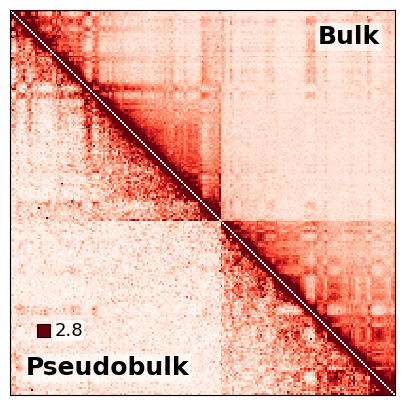

[OK] -> /home/jmj7858/epifluidlab/sc_nomehic_cellline/gm_sc_new/hic_comparison/figures/gm_heatmap_chr1_combined_main.pdf


In [ ]:
# BIN_HEATMAP moved here from the all-chromosome heatmap cell, which was
# removed: only the chr1 main-figure heatmap is published.
BIN_HEATMAP = 1_000_000

# chr1 combined (split) heatmap for the MAIN FIGURE
# upper triangle = Bulk, lower triangle = Pseudobulk; no colorbar, but a small square on lower left with max value.
import matplotlib as mpl

CHROM_MAIN = "chr1"
a_sc, a_bulk = prep_pair(CHROM_MAIN, BIN_HEATMAP, balance=True, drop_lowcov=True)
n = a_sc.shape[0]
split = np.zeros((n, n))
iu, ju = np.triu_indices(n, k=1); il, jl = np.tril_indices(n, k=-1)
split[iu, ju] = a_bulk[iu, ju]      # upper triangle -> Bulk
split[il, jl] = a_sc[il, jl]        # lower triangle -> Pseudobulk
both = np.concatenate([a_sc.ravel(), a_bulk.ravel()])
v = np.nanpercentile(both[np.isfinite(both)], PCT)
if not np.isfinite(v) or v <= 0:
    v = 1.0
max_val = v

with mpl.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "font.family": "sans-serif",
                     "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"]}):
    fig, ax = plt.subplots(figsize=(5, 5))
    im = ax.imshow(split, vmin=0, vmax=v, cmap="Reds", interpolation="none")
    ax.set_xticks([]); ax.set_yticks([])           # no bin index, no axis labels
    bbox = dict(facecolor="white", alpha=0.6, edgecolor="none", pad=1.5)
    ax.text(0.96, 0.96, "Bulk", transform=ax.transAxes, ha="right", va="top",
            fontsize=18, fontweight="bold", bbox=bbox)
    ax.text(0.04, 0.04, "Pseudobulk", transform=ax.transAxes, ha="left", va="bottom",
            fontsize=18, fontweight="bold", bbox=bbox)

    # Add small square patch indicating the maximum value and a text box showing that value
    from matplotlib.patches import Rectangle

    # Position: inset at lower left, above/horiz to pseudobulk label (axes fraction, e.g., [0.08, 0.09, 0.07, 0.07])
    square_size = 0.035  # fraction of axes
    left = 0.07
    bottom = 0.15
    rect = Rectangle((left, bottom), square_size, square_size, transform=ax.transAxes,
                     facecolor=plt.get_cmap("Reds")(1.0), edgecolor="black", lw=0.8, clip_on=False)
    ax.add_patch(rect)
    # Value label: right of the square, vertically centered
    ax.text(left + square_size + 0.01, bottom + square_size/2, f"{max_val:.2g}", 
            transform=ax.transAxes, va="center", ha="left", fontsize=13, 
            bbox=dict(facecolor="white", alpha=0.8, edgecolor="none", pad=0.8))

    out_main = os.path.join(OUT_FIG_DIR, f"gm_heatmap_{CHROM_MAIN}_combined_main_dot.pdf")
    fig.savefig(out_main, bbox_inches="tight", dpi=2400); plt.show()
print("[OK] ->", out_main)


In [ ]:
# SCC @ 1 Mb -- raw contacts with a 95th-percentile clip.
# This is the published measure. IC-balanced variants were evaluated during
# development and not used; see this folder's README.
# NOTE: SCC uses drop_lowcov=False (prep_pair default). Dropping bins would
# corrupt the genomic distances HiCRep relies on.
BIN_SCC = 1_000_000

def clip95(m):
    return np.minimum(m, np.percentile(m, 95))

rows_c = []
for chrom in CHROMS:
    sc_r, bk_r = prep_pair(chrom, BIN_SCC, balance=False)   # raw, un-balanced
    if sc_r is None:
        continue
    rows_c.append({"chrom": chrom,
                   "SCC_raw_clip95": compute_scc(clip95(sc_r), clip95(bk_r),
                                                 chrom, BIN_SCC)})
df_c = pd.DataFrame(rows_c)
df_c["flag"] = np.where(df_c.chrom.eq("chr4"), "outlier (excl.)", "")
display(df_c.round(3))

keep_c = df_c[df_c.chrom != "chr4"]
print(f"\nraw + 95th-percentile clip @ {LAB[BIN_SCC]} (excluding chr4):")
print(f"  median = {keep_c.SCC_raw_clip95.median():.3f}"
      f"   mean = {keep_c.SCC_raw_clip95.mean():.3f}")


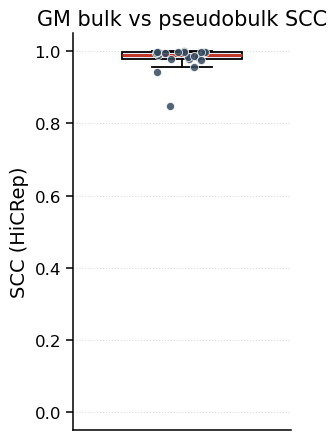

raw + 95pct clip @ 1Mb (excl chr4):  median = 0.989   n = 21
[OK] -> /home/jmj7858/epifluidlab/sc_nomehic_cellline/gm_sc_new/hic_comparison/figures/gm_scc_raw_clip95_only_1Mb.pdf


In [43]:
# single boxplot: raw + 95th-percentile clip SCC only -- publication style
import matplotlib as mpl

kk = keep_c.dropna(subset=["SCC_raw_clip95"])
vals = kk.SCC_raw_clip95.values

# vector-safe, legible defaults (journals require editable TrueType, not Type-3)
pub = {
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 13, "axes.titlesize": 15, "axes.labelsize": 14,
    "xtick.labelsize": 12, "ytick.labelsize": 12, "axes.linewidth": 1.1,
    "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.transparent": False,
}
with mpl.rc_context(pub):
    fig, ax = plt.subplots(figsize=(3.2, 4.6))
    ax.boxplot([vals], widths=0.55, showfliers=False, patch_artist=True,
               medianprops=dict(color="#c0392b", linewidth=2.2),
               boxprops=dict(facecolor="#eaf2f8", edgecolor="black", linewidth=1.3),
               whiskerprops=dict(color="black", linewidth=1.3),
               capprops=dict(color="black", linewidth=1.3))
    # jittered per-chromosome points (seeded for reproducibility)
    rng = np.random.default_rng(0)
    jit = rng.uniform(-0.12, 0.12, size=len(vals))
    ax.scatter(1 + jit, vals, s=34, color="#34495e", alpha=0.85,
               edgecolor="white", linewidth=0.6, zorder=3)

    ax.set_xticks([])  # empty -> no tick marks or labels (flat bottom axis)
    ax.set_xlim(0.5, 1.5); ax.set_ylim(-0.05, 1.05)
    ax.set_ylabel("SCC (HiCRep)")
    ax.set_title("GM bulk vs pseudobulk SCC")
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True); ax.yaxis.grid(True, ls=":", alpha=0.45)
    ax.tick_params(width=1.1, length=5)
    fig.tight_layout()
    fig.savefig(os.path.join(OUT_FIG_DIR, "gm_scc_raw_clip95_only_1Mb.pdf"))
    plt.show()

print(f"raw + 95pct clip @ {LAB[BIN_SCC]} (excl chr4):  median = {np.median(vals):.3f}   n = {len(vals)}")
print("[OK] ->", os.path.join(OUT_FIG_DIR, "gm_scc_raw_clip95_only_1Mb.pdf"))


Raw + 95pct-clip SCC across resolutions (chr4 excluded):


,median,mean,std,n
1Mb,0.99,0.98,0.03,21.0
500kb,0.99,0.99,0.02,21.0
250kb,0.99,0.99,0.01,21.0


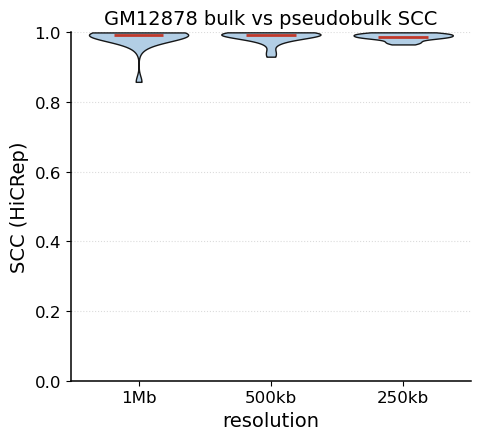

[OK] -> /home/jmj7858/epifluidlab/sc_nomehic_cellline/gm_sc_new/hic_comparison/figures/gm_scc_rawclip_by_resolution.pdf


In [20]:
# raw + 95th-percentile clip SCC across resolutions -- violin (1Mb, 500kb, 250kb)
import matplotlib as mpl
def clip95(m):
    return np.minimum(m, np.percentile(m, 95))

RES = [1_000_000, 500_000, 250_000]
raw_by_res = {}
for bs in RES:
    vals = []
    for chrom in CHROMS:
        if chrom == "chr4":                      # structural outlier, excluded
            continue
        sc_r, bk_r = prep_pair(chrom, bs, balance=False)
        if sc_r is None:
            continue
        vals.append(compute_scc(clip95(sc_r), clip95(bk_r), chrom, bs))
    raw_by_res[bs] = np.array(vals)

summ = pd.DataFrame(
    {LAB[bs]: [np.median(raw_by_res[bs]), np.mean(raw_by_res[bs]),
               np.std(raw_by_res[bs]), len(raw_by_res[bs])] for bs in RES},
    index=["median", "mean", "std", "n"]).T
print("Raw + 95pct-clip SCC across resolutions (chr4 excluded):")
# Only display rounded summary to fewer decimals for clarity
display(summ.round(2))

with mpl.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "font.family": "sans-serif",
                     "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
                     "font.size": 13, "axes.titlesize": 14, "axes.labelsize": 14,
                     "xtick.labelsize": 12, "ytick.labelsize": 12, "axes.linewidth": 1.1,
                     "savefig.dpi": 300, "savefig.bbox": "tight"}):
    data = [raw_by_res[bs] for bs in RES]
    labels = [LAB[bs] for bs in RES]
    pos = np.arange(1, len(RES) + 1)

    fig, ax = plt.subplots(figsize=(5.0, 4.6))
    parts = ax.violinplot(data, positions=pos, widths=0.75,
                          showmedians=True, showextrema=False)
    for b in parts["bodies"]:
        b.set_facecolor("#aac9e3"); b.set_edgecolor("black")
        b.set_alpha(0.9); b.set_linewidth(1.0)
    parts["cmedians"].set_color("#c0392b"); parts["cmedians"].set_linewidth(2.0)

    ax.set_xticks(pos); ax.set_xticklabels(labels)
    # Set y-axis limits from 0 to 1 to avoid showing too much detail
    ax.set_ylim(0, 1.0)
    ax.set_ylabel("SCC (HiCRep)"); ax.set_xlabel("resolution")
    ax.set_title("GM12878 bulk vs pseudobulk SCC")
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True); ax.yaxis.grid(True, ls=":", alpha=0.45)
    fig.tight_layout()
    fig.savefig(os.path.join(OUT_FIG_DIR, "gm_scc_rawclip_by_resolution.pdf")); plt.show()
print("[OK] ->", os.path.join(OUT_FIG_DIR, "gm_scc_rawclip_by_resolution.pdf"))
